# KDD Cup 1999 — Dataset Exploration

Earliest IDS benchmark, derived from the 1998 DARPA evaluation experiment.

**Files used:** `kddcup.data/kddcup.data` (full dataset, ~4.9 M rows), `kddcup.names` (column names), `corrected` (labelled test set).

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

BASE = '../../dataset/kddcup99/'

## 1 · Load Column Names

In [3]:
# First line of kddcup.names is the label list; remaining lines are 'feature: type.'
with open(BASE + 'kddcup.names') as f:
    lines = f.read().splitlines()

feature_names = [l.split(':')[0].strip() for l in lines[1:] if ':' in l]
feature_names.append('label')
print(f'Total columns: {len(feature_names)}')
print(feature_names)

Total columns: 42
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label']


## 2 · Load Data (Full Dataset)

In [4]:
df = pd.read_csv(BASE + 'kddcup.data/kddcup.data',
                 header=None, names=feature_names)
print(f'Shape: {df.shape}')
df.head()

Shape: (4898431, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,http,SF,215,45076,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0,0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,normal.
1,0,tcp,http,SF,162,4528,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1,1,1.0,0.0,1.00,0.0,0.0,0.0,0.0,0.0,normal.
2,0,tcp,http,SF,236,1228,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2,2,1.0,0.0,0.50,0.0,0.0,0.0,0.0,0.0,normal.
3,0,tcp,http,SF,233,2032,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3,3,1.0,0.0,0.33,0.0,0.0,0.0,0.0,0.0,normal.
4,0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,3,3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4,4,1.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,normal.


## 3 · Basic Inspection

In [5]:
print('--- dtypes ---')
print(df.dtypes.value_counts())
print()
print('--- categorical columns ---')
cat_cols = df.select_dtypes('object').columns.tolist()
print(cat_cols)
print()
print('--- numeric columns ---')
num_cols = df.select_dtypes('number').columns.tolist()
print(f'{len(num_cols)} numeric features')

--- dtypes ---
int64      23
float64    15
str         4
Name: count, dtype: int64

--- categorical columns ---
['protocol_type', 'service', 'flag', 'label']

--- numeric columns ---
38 numeric features


/tmp/ipykernel_577168/1358007310.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes('object').columns.tolist()


## 4 · Missing Values & Duplicates

In [6]:
print('Missing values per column:')
print(df.isnull().sum()[df.isnull().sum() > 0].to_string() or 'None')
print()
print(f'Duplicate rows: {df.duplicated().sum()}')

Missing values per column:
Series([], )

Duplicate rows: 3823439


## 5 · Label Distribution

Multi-class label counts:
label
smurf.              2807886
neptune.            1072017
normal.              972781
satan.                15892
ipsweep.              12481
portsweep.            10413
nmap.                  2316
back.                  2203
warezclient.           1020
teardrop.               979
pod.                    264
guess_passwd.            53
buffer_overflow.         30
land.                    21
warezmaster.             20
imap.                    12
rootkit.                 10
loadmodule.               9
ftp_write.                8
multihop.                 7
phf.                      4
perl.                     3
spy.                      2


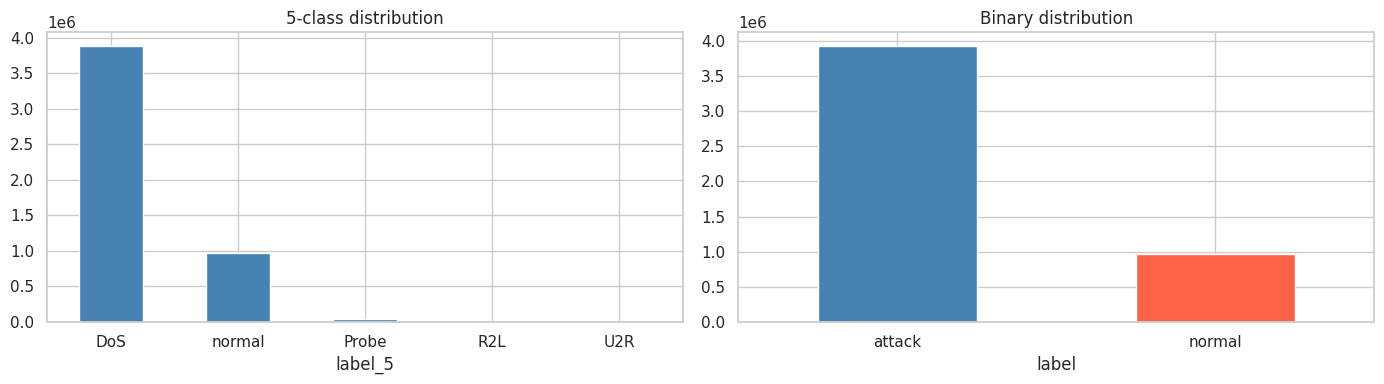

In [7]:
# Raw attack-type labels
print('Multi-class label counts:')
print(df['label'].value_counts().to_string())

# Map to 5 high-level categories
dos   = {'back','land','neptune','pod','smurf','teardrop'}
probe = {'ipsweep','nmap','portsweep','satan'}
r2l   = {'ftp_write','guess_passwd','imap','multihop','phf','spy','warezclient','warezmaster'}
u2r   = {'buffer_overflow','loadmodule','perl','rootkit'}

def coarse(lbl):
    lbl = lbl.rstrip('.')
    if lbl == 'normal': return 'normal'
    if lbl in dos:      return 'DoS'
    if lbl in probe:    return 'Probe'
    if lbl in r2l:      return 'R2L'
    if lbl in u2r:      return 'U2R'
    return 'other'

df['label_5'] = df['label'].apply(coarse)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['label_5'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('5-class distribution'); axes[0].tick_params(axis='x', rotation=0)
df['label'].apply(lambda x: 'attack' if x.rstrip('.') != 'normal' else 'normal') \
    .value_counts().plot(kind='bar', ax=axes[1], color=['steelblue','tomato'])
axes[1].set_title('Binary distribution'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

## 6 · Categorical Feature Cardinality

In [8]:
for col in cat_cols:
    if col == 'label': continue
    print(f'{col}: {df[col].nunique()} unique values → {df[col].unique().tolist()}')

protocol_type: 3 unique values → ['tcp', 'udp', 'icmp']
service: 70 unique values → ['http', 'smtp', 'domain_u', 'auth', 'finger', 'telnet', 'eco_i', 'ftp', 'ntp_u', 'ecr_i', 'other', 'urp_i', 'private', 'pop_3', 'ftp_data', 'netstat', 'daytime', 'ssh', 'echo', 'time', 'name', 'whois', 'domain', 'mtp', 'gopher', 'remote_job', 'rje', 'ctf', 'supdup', 'link', 'systat', 'discard', 'X11', 'shell', 'login', 'imap4', 'nntp', 'uucp', 'pm_dump', 'IRC', 'Z39_50', 'netbios_dgm', 'ldap', 'sunrpc', 'courier', 'exec', 'bgp', 'csnet_ns', 'http_443', 'klogin', 'printer', 'netbios_ssn', 'pop_2', 'nnsp', 'efs', 'hostnames', 'uucp_path', 'sql_net', 'vmnet', 'iso_tsap', 'netbios_ns', 'kshell', 'urh_i', 'http_2784', 'harvest', 'aol', 'tftp_u', 'http_8001', 'tim_i', 'red_i']
flag: 11 unique values → ['SF', 'S2', 'S1', 'S3', 'OTH', 'REJ', 'RSTO', 'S0', 'RSTR', 'RSTOS0', 'SH']


## 7 · Numeric Feature Distributions

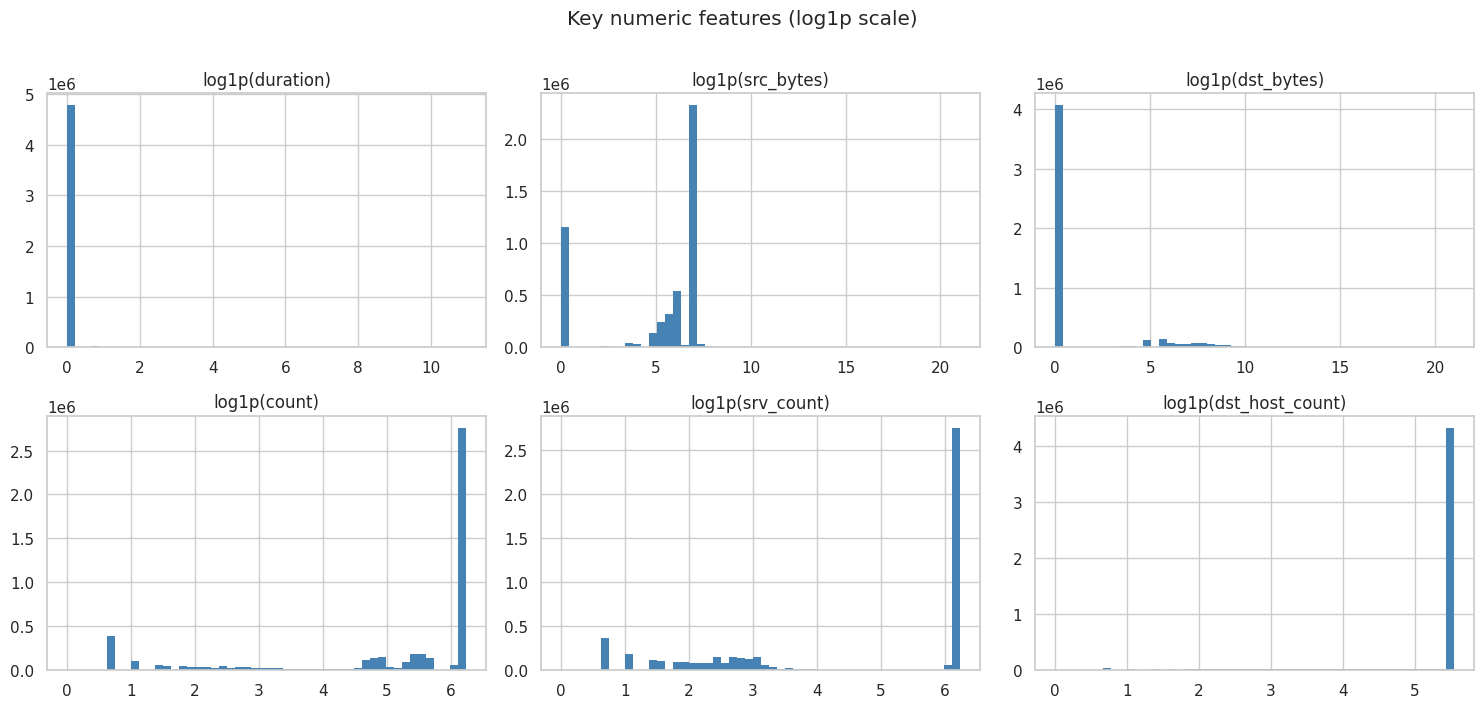

In [9]:
# Log-scale histograms for highly skewed byte/count features
key_feats = ['duration','src_bytes','dst_bytes','count','srv_count','dst_host_count']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, feat in zip(axes.flat, key_feats):
    vals = df[feat].clip(lower=0)
    ax.hist(np.log1p(vals), bins=50, color='steelblue', edgecolor='none')
    ax.set_title(f'log1p({feat})')
plt.suptitle('Key numeric features (log1p scale)', y=1.01)
plt.tight_layout(); plt.show()

## 8 · Correlation (Numeric Features)

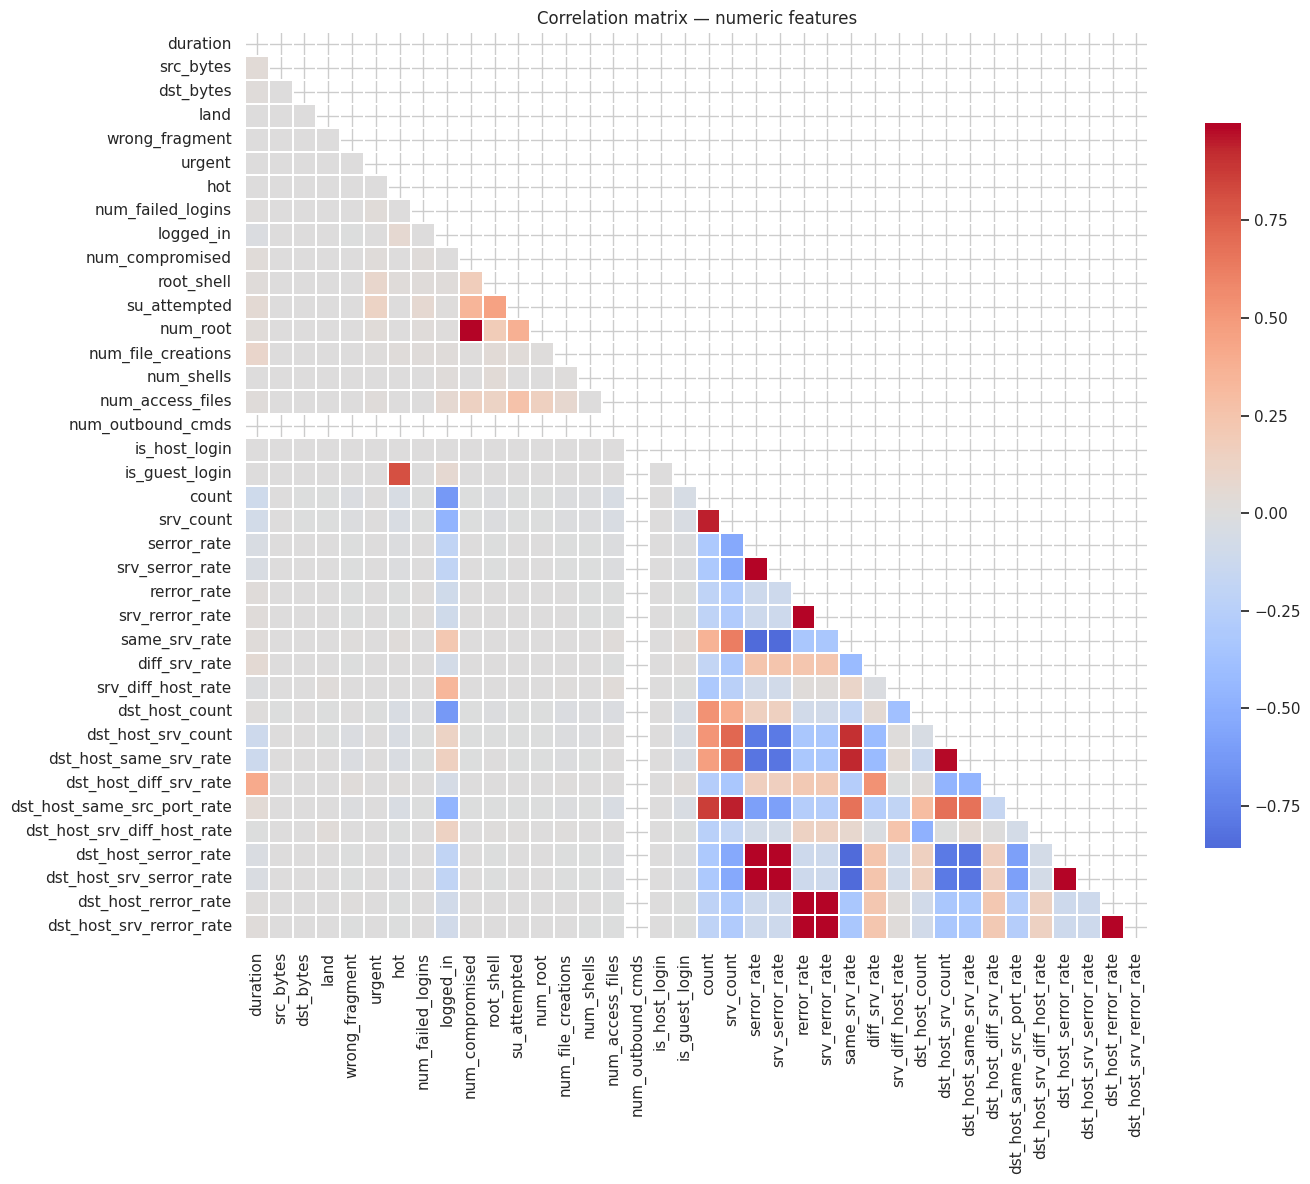

In [10]:
fig, ax = plt.subplots(figsize=(14, 12))
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0,
            linewidths=0.3, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation matrix — numeric features')
plt.tight_layout(); plt.show()

## 9 · Preprocessing Checklist

| Step | Required | Notes |
|---|---|---|
| Strip trailing `.` from labels | Yes | e.g. `normal.` → `normal` |
| One-hot encode categoricals | Yes | `protocol_type` (3), `service` (66), `flag` (11) |
| Log/MinMax scale numerics | Yes | Highly skewed byte/count features |
| Remove duplicates | Optional | ~80 % of rows are exact duplicates in full set |
| Map labels to integers | Yes | For model input |
| Handle class imbalance | Yes | DoS dominates (~79 %); consider oversampling/weighting |

## 10 · Train / Test Split

In [11]:
from sklearn.preprocessing import LabelEncoder

df['label_clean'] = df['label'].str.rstrip('.')
le = LabelEncoder()
df['y'] = le.fit_transform(df['label_clean'])

# Use the labelled test set as hold-out when available; otherwise stratified split
X = df.drop(columns=['label', 'label_5', 'label_clean', 'y'])
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')
print()
for split, ys in [('Train', y_train), ('Test', y_test)]:
    counts = pd.Series(le.inverse_transform(ys)).value_counts(normalize=True)
    print(f'{split} class proportions:')
    print(counts.apply(lambda x: f'{x:.2%}').to_string(), '\n')

Train: (3918744, 41)  |  Test: (979687, 41)

Train class proportions:
smurf              57.32%
neptune            21.88%
normal             19.86%
satan               0.32%
ipsweep             0.25%
portsweep           0.21%
nmap                0.05%
back                0.04%
warezclient         0.02%
teardrop            0.02%
pod                 0.01%
guess_passwd        0.00%
buffer_overflow     0.00%
land                0.00%
warezmaster         0.00%
imap                0.00%
rootkit             0.00%
loadmodule          0.00%
ftp_write           0.00%
multihop            0.00%
phf                 0.00%
perl                0.00%
spy                 0.00% 

Test class proportions:
smurf              57.32%
neptune            21.88%
normal             19.86%
satan               0.32%
ipsweep             0.25%
portsweep           0.21%
nmap                0.05%
back                0.05%
warezclient         0.02%
teardrop            0.02%
pod                 0.01%
guess_passwd        

## 11 · Summary

- **Size:** ~4.9 M rows (full dataset)
- **Features:** 38 numeric + 3 symbolic (one-hot → ~115 total after encoding)
- **Labels:** 23 fine-grained attack types → map to 5 categories or binary
- **Key issues:** label trailing `.`, massive class imbalance (DoS ~79 %), high collinearity in rate features, many zero-heavy numeric columns, ~78 % duplicate rows
- **Recommended for SNN:** log1p + MinMax scaling; one-hot categoricals; consider deduplication before training; stratified split